# Tumour Response Waterfall Plot

**Family:** Scientific &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Scientific:* Specialised plots for statistics and scientific research: survival, effect sizes, agreement, omics, study flow and longitudinal data.

## Design purpose

One vertical bar per patient shows the best percentage change in tumour size from baseline, sorted from worst to best. Response categories (RECIST) can be read straight off the threshold lines.

## When to use

- Show tumour shrinkage in single-arm or early-phase oncology trials
- Show any per-subject percent change where thresholds define categories

## Avoid when

- Time course or durability matters (pair it with a swimmer or spider plot)
- Comparing arms of very different sizes in one panel (use one panel per arm)

## Alternatives

- Spider plot (change over time per patient)
- Swimmer plot
- Diverging bar chart

## Design tips

- Draw RECIST reference lines at +20% (progression) and −30% (partial response)
- Color bars by best overall response with an ordered palette, and keep the bar gaps small

## Example

Best % change in the sum of target-lesion diameters for 40 synthetic patients.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(17)
change = np.clip(rng.normal(-18, 32, 40), -100, 75).round(1)
change[rng.choice(40, 2, replace=False)] = -100
bor = np.select([change <= -100, change <= -30, change >= 20],
                ["Complete response", "Partial response", "Progressive disease"], "Stable disease")
df = pd.DataFrame({"patient": range(1, 41), "best_change": change, "response": bor})
df = df.sort_values("best_change", ascending=False).reset_index(drop=True)
df.response.value_counts()

response
Stable disease         19
Partial response       15
Progressive disease     4
Complete response       2
Name: count, dtype: int64

### Plot

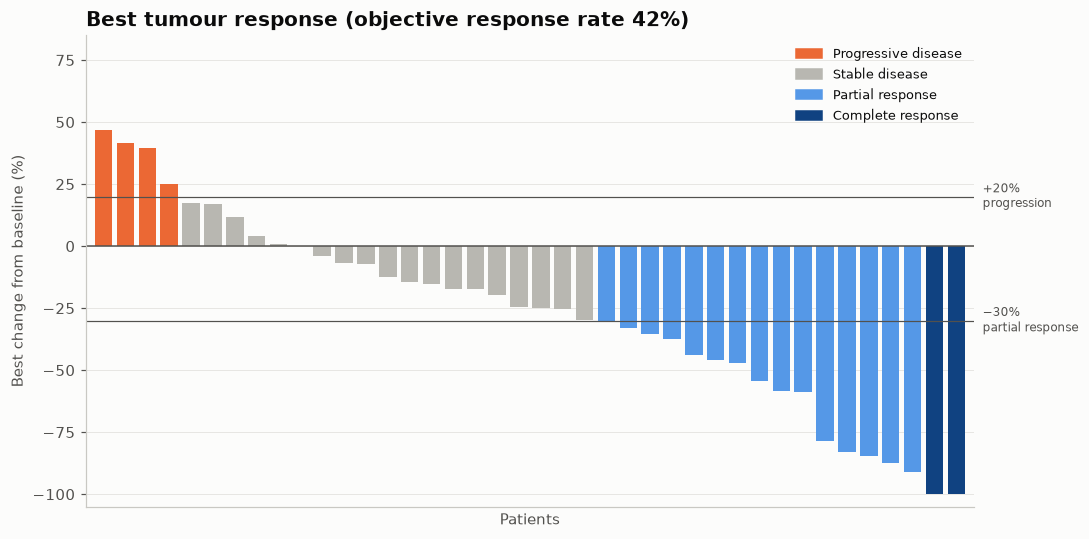

In [3]:
colors = {"Progressive disease": PALETTE[1], "Stable disease": GRAY,
          "Partial response": "#5598e7", "Complete response": "#104281"}
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(df.index, df.best_change, color=df.response.map(colors), width=0.8)
for v, lab in [(20, "+20%\nprogression"), (-30, "−30%\npartial response")]:
    ax.axhline(v, color="#52514e", linewidth=0.8)
    ax.text(1.01, v, lab, transform=ax.get_yaxis_transform(), va="center", fontsize=8, color="#52514e")
ax.axhline(0, color="#52514e", linewidth=1)
ax.set_xticks([]); ax.set_xlim(-0.8, len(df) - 0.2)
ax.grid(axis="x", visible=False)
ax.set_ylim(-105, 85)
ax.set_ylabel("Best change from baseline (%)"); ax.set_xlabel("Patients")
orr = df.response.isin(["Complete response", "Partial response"]).mean()
ax.set_title(f"Best tumour response (objective response rate {orr:.0%})")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=k) for k, c in colors.items()], loc="upper right", fontsize=8.5)
fig.tight_layout()
plt.show()

## How to read it

Each bar is a patient. Bars below −30% are responders and bars above +20% progressed. The longer the blue section, the more active the drug.

---
Standalone script: [`tumor_response_waterfall.py`](tumor_response_waterfall.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)